In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression 

In [4]:
wm_data = pd.read_csv('wm_data2.csv')
wm_data.head()

,Unnamed: 0,Record ID,Product ID,Product Name,Category,Warehouse,Location,Quantity,Price,Supplier,Status,Last Restocked
0,0,1,1102,gadget y,electronics,Warehouse 2,Aisle 1,300.0,9.99,Supplier C,in stock,NaN
1,1,2,1435,gadget y,electronics,Warehouse 2,Aisle 4,200.0,19.99,Supplier C,out of stock,NaN
2,2,3,1860,widget a,clothing,Warehouse 2,Aisle 3,100.0,19.99,Supplier B,in stock,20/12/2022
3,3,4,1270,gadget z,toys,Warehouse 2,Aisle 4,50.0,49.99,Supplier B,in stock,20/12/2022
4,4,5,1106,widget a,furniture,Warehouse 3,Aisle 3,200.0,9.99,Supplier D,out of stock,25/04/2023


In [70]:
wm_data.head()

,Record ID,Product ID,Product Name,Category,Warehouse,Location,Quantity,Price,Supplier,Status,Last Restocked
0,1,1102,gadget y,electronics,Warehouse 2,Aisle 1,300.0,9.99,Supplier C,in stock,NaN
1,2,1435,gadget y,electronics,Warehouse 2,Aisle 4,200.0,19.99,Supplier C,out of stock,NaN
2,3,1860,widget a,clothing,Warehouse 2,Aisle 3,100.0,19.99,Supplier B,in stock,20/12/2022
3,4,1270,gadget z,toys,Warehouse 2,Aisle 4,50.0,49.99,Supplier B,in stock,20/12/2022
4,5,1106,widget a,furniture,Warehouse 3,Aisle 3,200.0,9.99,Supplier D,out of stock,25/04/2023


In [5]:
wm_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Unnamed: 0      1000 non-null   int64  
 1   Record ID       1000 non-null   int64  
 2   Product ID      1000 non-null   int64  
 3   Product Name    1000 non-null   str    
 4   Category        1000 non-null   str    
 5   Warehouse       1000 non-null   str    
 6   Location        1000 non-null   str    
 7   Quantity        842 non-null    float64
 8   Price           793 non-null    float64
 9   Supplier        1000 non-null   str    
 10  Status          1000 non-null   str    
 11  Last Restocked  800 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 93.9 KB


In [25]:
columns = wm_data.columns
for column in columns:
    print(f'{column}: {wm_data[column].unique()} - {len(wm_data[column].unique())}')

Product ID: [1102 1435 1860 1270 1106 1071 1700 1020 1614 1121 1466 1214 1330 1458
 1087 1372 1099 1871 1663 1130 1661 1308 1769 1343 1491 1413 1805 1385
 1191 1955 1276 1160 1459 1313 1021 1252 1747 1856 1560 1474 1058 1510
 1681 1475 1699 1975 1782 1189 1957 1686 1562 1875 1566 1243 1831 1504
 1484 1818 1646 1840 1166 1273 1387 1600 1315 1013 1241 1776 1345 1564
 1897 1339 1091 1366 1454 1427 1508 1775 1942 1034 1205 1080 1931 1561
 1001 1389 1565 1105 1771 1821 1476 1702 1401 1729 1555 1161 1201 1995
 1269 1862 1815 1455 1461 1726 1251 1701 1295 1724 1719 1748 1337 1878
 1052 1791 1921 1216 1763 1187 1379 1492 1040 1156 1014 1812 1064 1838
 1520 1128 1647 1471 1062 1138 1498 1592 1391 1674 1418 1288 1378 1772
 1489 1230 1027 1134 1200 1839 1779 1929 1032 1047 1502 1406 1573 1727
 1804 1098 1683 1725 1986 1546 1960 1738 1612 1642 1768 1004 1217 1766
 1397 1870 1794 1392 1206 1857 1553 1891 1460 1690 1574 1863 1742 1240
 1563 1095 1899 1733 1654 1170 1540 1035 1524 1159 1698 1242 1085

In [43]:
wm_data.loc[wm_data['Quantity']=='two hundred', 'Quantity'] = '200'

In [44]:
wm_data['Quantity'] = wm_data['Quantity'].astype('float64')

In [47]:
wm_data['Category'] = wm_data['Category'].str.lower()
wm_data['Status'] = wm_data['Status'].str.lower()

In [51]:
wm_data.loc[wm_data['Last Restocked']=='unknown', 'Last Restocked'] = None

In [54]:
wm_data.drop_duplicates()

,Product ID,Product Name,Category,Warehouse,Location,Quantity,Price,Supplier,Status,Last Restocked
0,1102,gadget y,electronics,Warehouse 2,Aisle 1,300.0,9.99,Supplier C,in stock,NaN
1,1435,gadget y,electronics,Warehouse 2,Aisle 4,200.0,19.99,Supplier C,out of stock,NaN
2,1860,widget a,clothing,Warehouse 2,Aisle 3,100.0,19.99,Supplier B,in stock,20/12/2022
3,1270,gadget z,toys,Warehouse 2,Aisle 4,50.0,49.99,Supplier B,in stock,20/12/2022
4,1106,widget a,furniture,Warehouse 3,Aisle 3,200.0,9.99,Supplier D,out of stock,25/04/2023
...,...,...,...,...,...,...,...,...,...,...
995,1009,widget b,furniture,Warehouse 2,Aisle 2,100.0,NaN,Supplier C,in stock,15/01/2023
996,1823,gadget y,electronics,Warehouse 2,Aisle 3,300.0,19.99,Supplier B,in stock,20/12/2022
997,1797,gadget z,toys,Warehouse 3,Aisle 5,150.0,9.99,Supplier C,low stock,05/03/2023
998,1241,widget c,furniture,Warehouse 2,Aisle 2,100.0,49.99,Supplier C,low stock,20/12/2022


In [64]:
wm_data[wm_data.duplicated(subset=['Product ID'], keep=False)].sort_values('Product ID')

,Product ID,Product Name,Category,Warehouse,Location,Quantity,Price,Supplier,Status,Last Restocked
90,1001,gadget x,toys,Warehouse 3,Aisle 3,150.0,19.99,Supplier C,low stock,25/04/2023
367,1001,widget a,furniture,Warehouse 2,Aisle 5,300.0,19.99,Supplier A,low stock,NaN
284,1001,gadget y,furniture,Warehouse 1,Aisle 5,200.0,49.99,Supplier C,low stock,20/12/2022
179,1004,gadget z,clothing,Warehouse 1,Aisle 3,50.0,19.99,Supplier B,out of stock,NaN
578,1004,gadget y,clothing,Warehouse 3,Aisle 3,300.0,29.99,Supplier A,in stock,05/03/2023
...,...,...,...,...,...,...,...,...,...,...
104,1995,gadget y,toys,Warehouse 1,Aisle 4,300.0,19.99,Supplier D,out of stock,NaN
289,1996,widget b,electronics,Warehouse 3,Aisle 1,200.0,9.99,Supplier A,in stock,15/01/2023
643,1996,widget b,furniture,Warehouse 3,Aisle 2,100.0,19.99,Supplier C,low stock,20/12/2022
631,1998,gadget y,electronics,Warehouse 3,Aisle 3,NaN,NaN,Supplier B,in stock,05/03/2023


In [69]:
wm_data.insert(0,'Record ID', range(1, len(wm_data)+1))

In [77]:
num_df = wm_data.select_dtypes(['float64','int64'])
corr_matrix = num_df.corr()
corr_matrix

,Record ID,Product ID,Quantity,Price
Record ID,1.000000,0.002947,-0.008919,-0.020668
Product ID,0.002947,1.000000,0.050203,0.051245
Quantity,-0.008919,0.050203,1.000000,-0.064788
Price,-0.020668,0.051245,-0.064788,1.000000


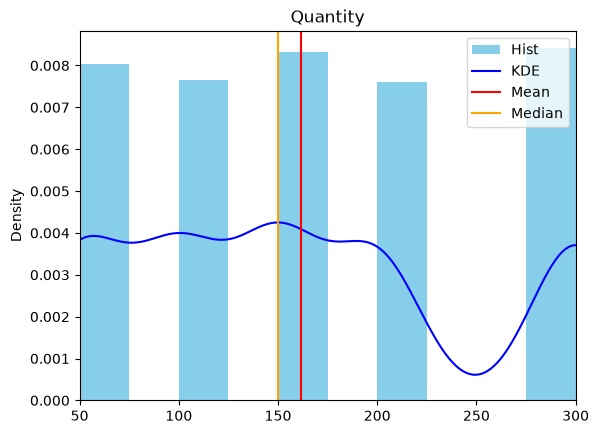

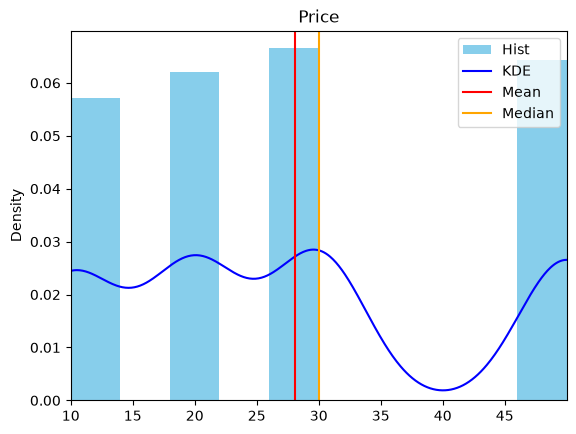

In [85]:
columns_num = num_df.drop(['Record ID','Product ID'], axis=1).columns
for column in columns_num:
    num_df[column].plot(kind='hist', color='skyblue', bins=10, density=True, label='Hist')
    num_df[column].plot(kind='kde', color='blue', label='KDE')
    plt.axvline(num_df[column].mean(), color='red', label='Mean')
    plt.axvline(num_df[column].median(), color='orange', label='Median')
    plt.xlim(num_df[column].min(),num_df[column].max())
    plt.legend()
    plt.title(column)
    plt.show()
    

In [19]:
wm_data['Missed Quantity'] = wm_data['Quantity'].isna().astype(int)
wm_data['Missed Price'] = wm_data['Price'].isna().astype(int)
wm_data['Missed Last Restocked'] = wm_data['Last Restocked'].isna().astype(int)
wm_data = wm_data.drop('Unnamed: 0', axis=1)

In [20]:
wm_data.to_csv('warehouse_messy_data_cleaned.csv', index=False)